# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications**

**Student:** Firdaous Boulben  
**Academic Year:** 2026-2027

## 1. Introduction

This practical lab explores the deployment and use of Large Language Models (LLMs) locally using Ollama. It focuses on interacting with locally hosted models through the terminal and Python, accessing them through a REST API, and developing simple AI applications without relying on external inference services.

## 2. Objectives

The main objectives of this lab are to:
- Understand how Ollama runs and manages local language models.
- Download and execute LLMs such as Qwen, Gemma, or Llama.
- Interact with local models through the command line and REST API.
- Develop Python applications using the requests library.
- Explore model responses and experiment with different prompts and configurations.
- Understand the advantages and limitations of running AI models locally.

## 3. Technologies and Environment

- **Ollama:** Local LLM runtime and model management.
- **Python:** Application development and API interaction.
- **REST API:** Communication with the local Ollama service.
- **Requests:** Python library for sending HTTP requests.
- **LLMs:** Locally executed models, such as Qwen, Gemma, or Llama.
- **Optional:** Open WebUI for graphical interaction with local models.

The experiments use Ollama's local HTTP service, typically available at `http://localhost:11434`. Hardware requirements depend on the selected model and its configuration; GPU acceleration is optional.

# Part 1 — Understanding Local AI

## 1. Cloud AI vs. Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```

The main difference is where the model runs. Cloud AI relies on remote infrastructure, whereas local AI uses a model installed on the user's own machine. Ollama provides a local HTTP API that allows applications to communicate with the model.

## 2. Advantages and limitations of Local AI

| Aspect | Explanation |
|--------|-------------|
| **Privacy** | Prompts and responses can remain on the local machine instead of being sent to a cloud inference provider. |
| **Offline operation** | Once Ollama and the required model are installed, inference can generally run without an internet connection. |
| **Cost** | No per-token API charge is required for local inference, although electricity, hardware, and maintenance still have costs. |
| **Performance** | Speed depends on the model size, available RAM, CPU/GPU, and task complexity. |
| **Model capabilities** | Smaller local models may perform less effectively than more powerful cloud models on complex tasks. |


# Part 2 — Installing Ollama

## Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
System  : Windows 10


In [2]:
!pip --version

pip 25.1.1 from C:\Users\asus\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pip (python 3.10)



The environment verification confirmed that Python 3.13.16 and pip 24.1.2 are installed on a Linux system. The Python version satisfies the minimum requirement of Python 3.10, so the environment is ready for the next steps.

## Exercise 2 — Install Ollama

**Step 1 — Install Ollama**

Ollama was installed locally on Windows using the official installation script: `irm https://ollama.com/install.ps1 | iex`



**Step 2 — Verify the installation**

In [3]:
!ollama --version

ollama version is 0.40.6


**Step 3 — Verify the server**

In [4]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


# Part 3 — Your First Local LLM

## Exercise 3 — Download a model

In [5]:
MODEL  = "qwen3.5"   # Model 1
MODEL2 = "gemma3"    # Model 2 (used in the comparison parts)

In [6]:
!ollama pull {MODEL}

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest 
pulling f836f08f9211: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 921 MB                         
pulling 02d45dc1cf45: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 5.6 GB                         
pulling b507b9c2f6ca: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   13 B                         
pulling 50cbab8a892c: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  11 KB                         
pulling 9371364b27a5: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   65 B                         
pulling 08f9698c1116: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  177 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
succes

In [7]:
!ollama list

NAME              ID              SIZE      MODIFIED     
qwen3.5:latest    56671c2ab938    6.6 GB    1 second ago    


The Qwen 3.5 model was downloaded successfully using Ollama. The `ollama list` command confirmed that the model is installed and available for local inference, with a reported size of 6.6 GB.

## Exercise 4 — Run the model

In [12]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=1200)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [13]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[480.1s]
Artificial intelligence refers to computer systems designed to mimic human cognitive abilities such as learning, problem-solving, and creativity. Instead of following strict instructions, these programs use algorithms to analyze data and improve their performance over time. You can see this technology in everyday tools like voice-activated speakers, navigation apps, and spam filters. As AI develops further, it is increasingly integrated into industries ranging from healthcare to finance to assist with complex decision-making. This advancement aims to augment human capabilities rather than replace them, helping us tackle challenges more efficiently.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[410.0s]
Imagine you have a really smart friend who never gets tired, never gets bored, and knows almost everything in the whole world! That is what **Artificial Intelligence** (AI) is like.

Here is

### Questions

1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

### Answers

1. Yes, the model produced different answers because each prompt specifies a different audience. It adapts the complexity, vocabulary, and level of detail to the intended reader.
2. No. The application communicates with Ollama's local API rather than a cloud-based LLM API.
3. Inference is performed locally on my computer, using the downloaded Qwen 3.5 model and the available CPU and/or GPU resources.
4. After downloading the model, inference can continue without an Internet connection, provided Ollama is running and the model is available locally.

# Part 4 — Experiment with Prompts

## Exercise 5 — Prompt engineering

In [14]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[797.5s]
Good morning, class! Please take your seats. Today we are diving into one of the most fundamental structures in computer science and mathematics: the **Directed Acyclic Graph**, often abbreviated as a **DAG**.

You have likely encountered graphs before—perhaps when studying social networks or simple maps. However, a DAG introduces two critical constraints that change how we analyze data flow, dependencies, and scheduling. Let's break this down step-by-step.

***

### 1. Definition

A **Directed Acyclic Graph (DAG)** is a type of finite graph where:
*   **Directed:** The edges (connections between nodes) have a specific direction. If there is an edge from node $u$ to node $v$, it can be written as $(u, v)$, meaning you can travel from $u$ to $v$, but not necessarily back the other way without intermediate nodes.
*   **Acyclic:** The graph contains no "cycles." A cycle would mean starting at a node, following the directed edges, and eventually returning to that exact same start 

In [15]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[774.8s]
Hello, everyone! Pull up a chair and let's talk about something that comes up all the time in programming and engineering: **DAGs**. Don't panic by the name—it breaks down into three very simple words once we understand them.

Think of a DAG as a **flowchart for tasks**, but with strict rules. It stands for:
*   **Directe:** Edges (the connections) point in one direction only. If you go from A to B, you can't walk back to A.
*   **Acyclic:** Ac means "without a cycle." You cannot draw a circle where you end up back where you started without passing through an edge again.

**The Concrete Example: Your Semester Schedule**

Imagine we are designing the map for your second year of courses. Let's say you need to satisfy these requirements:
1.  **CS101 (Intro to Python)** is required for **CS102 (Data Structures)**.
2.  **Math101 (Calculus)** is required for **Stats201**.
3.  **CS102** is recommended before taking **CS103 (Algorithms)**.

We draw a graph where every course is a dot 

### Questions

Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

### Answers

The two answers differ because of how the prompts are designed:

- **Role:** Both prompts assign the model the role of a university professor, encouraging an educational and explanatory tone.
- **Context:** Prompt A requests a complete explanation of DAGs, while Prompt B targets a first-year computer science student.
- **Constraints:** Prompt A requires five specific elements. Prompt B asks for simple language and one concrete example.
- **Output format:** Prompt A requires a structured answer with a definition, example, adjacency matrix, application, and Python code. Prompt B leaves the format more flexible.
- **Specificity:** Prompt A provides more detailed instructions, resulting in a longer, more technical answer. Prompt B focuses on simplicity and accessibility.

Prompt engineering helps control the content, complexity, and structure of a model's response. More detailed instructions generally produce more targeted answers, while simpler prompts can encourage more accessible explanations.

# Part 5 — Model Management

## Exercise 6 — List, show, and monitor models

In [16]:
!ollama list

NAME              ID              SIZE      MODIFIED    
qwen3.5:latest    56671c2ab938    6.6 GB    2 hours ago    


In [17]:
!ollama show {MODEL}

  Model
    architecture        qwen35    
    parameters          9.0B      
    context length      262144    
    embedding length    4096      
    quantization        Q4_K_M    
    requires            0.30.0    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    top_p               0.95    
    presence_penalty    1.5     
    temperature         1       
    top_k               20      

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [18]:
!ollama ps

NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [19]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M


Currently loaded in memory:


""


### Questions

1. What information do you get from `ollama list` vs `ollama ps`?
2. What is the difference between a model that is **downloaded** and one that is **loaded**?

### Answers

1. - `ollama list` displays downloaded models, including their names, IDs, sizes, and modification dates.
   - `ollama ps` displays models currently loaded in memory, including their size, processor allocation, context length, and remaining time before they are unloaded.
  
2. A downloaded model is stored on the computer and is ready to be used. A loaded model is active in memory (RAM and/or GPU memory) so Ollama can generate responses. A model can be downloaded without being loaded, and it may be unloaded after a period of inactivity to free up memory.

# Part 6 — Compare Two Local Models

The first model, qwen3.5:latest, is already installed locally. For the comparison, the second model is defined as gemma3. This model will be downloaded and evaluated alongside the first model to compare their response quality and generation speed.

In [21]:
!ollama pull {MODEL2}

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest 
pulling f06e91e18fc7: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 2.5 GB                         
pulling 7a50f9607a47: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 851 MB                         
pulling e0a42594d802: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  358 B                         
pulling dd084c7d92a3: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 8.4 KB                         
pulling 3116c5225075: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   77 B                         
pulling 4bf7b0a45f1a: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  144 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [22]:
!ollama list

NAME              ID              SIZE      MODIFIED       
gemma3:latest     68ceab7e468a    3.4 GB    16 seconds ago    
qwen3.5:latest    56671c2ab938    6.6 GB    3 hours ago       


## Exercise 7 — Same prompt, different models

In [23]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5

```python
from math import isqrt
from typing import Union

def is_prime(n: int) -> bool:
    """
    Determines whether a given integer is a prime number.

    A prime number is a natural number greater than 1 that has no positive 
    divisors other than 1 and itself.

    Args:
        n (int): The integer to check for primality. Accepts values >= 2.
                 Negative numbers, zero, and one are not considered prime.

    Returns:
        bool: True if `n` is a prime number, False otherwise.

    Examples:
        >>> is_prime(2)
        True
        >>> is_prime(17)
        True
        >>> is_prime(18)
        False
        >>> is_prime(-5)
        False
    """
    # Handle edge cases
    if n <= 1:
        return False
    if n == 2 or n == 3:
        return True
    if n % 2 == 0:
        return False

    # Check odd divisors up to √n
    limit = isqrt(n)
    for i in range(3, limit + 1, 2):
        if n % i == 0:
            return False
    return True


In [27]:
scores = {
    MODEL:  {"Response quality /5": 5, "Code correctness /5": 5},
    MODEL2: {"Response quality /5": 5, "Code correctness /5": 5},
}

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5,433.6,5,5
1,gemma3,318.2,5,5


**Test the generated code:**

In [28]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

In [29]:
from math import isqrt
from typing import Union

def is_prime(n: int) -> bool:
    # Handle edge cases
    if n <= 1:
        return False
    if n == 2 or n == 3:
        return True
    if n % 2 == 0:
        return False

    # Check odd divisors up to √n
    limit = isqrt(n)
    for i in range(3, limit + 1, 2):
        if n % i == 0:
            return False
    return True

candidate = is_prime

assert all(
    candidate(n) == is_prime_reference(n)
    for n in range(-5, 2000)
), "Incorrect!"

print("Qwen 3.5: Test passed!")

Qwen 3.5: Test passed!


In [30]:
def is_prime(number: int) -> bool:
    if number <= 1:
        return False

    # Iterate from 2 up to the square root of the number
    for i in range(2, int(number**0.5) + 1):
        if number % i == 0:
            return False

    return True

candidate = is_prime

assert all(
    candidate(n) == is_prime_reference(n)
    for n in range(-5, 2000)
), "Incorrect!"

print("Gemma 3: Test passed!")

Gemma 3: Test passed!


### Questions

1. Which model is faster?
2. Which produces better code?
3. Which uses more memory?
4. Which would you choose for programming assistance?
5. Is the largest model necessarily the best?

### Answers

1. Gemma 3 was faster, taking 318.2 seconds compared with 433.6 seconds for Qwen 3.5.
2. Both generated correct code and passed the tests. Qwen 3.5 used a slightly more optimized approach by skipping even divisors, while Gemma 3 provided simpler code that is easier for beginners to understand.
3. Qwen 3.5 is larger (6.6 GB) than Gemma 3 (3.4 GB), so it generally requires more memory to run.
4. I would choose Gemma 3 for this computer because it was faster and generated correct code while using a smaller model. Qwen 3.5 may be preferable when more advanced reasoning or additional capabilities are needed.
5. No. A larger model may offer stronger capabilities, but the best choice depends on code quality, speed, memory requirements, and the task. A smaller model can be more practical, especially on limited hardware.

# Part 7 — Using Local AI from Python

## Exercise 8 — Python + Ollama

Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```

In [31]:
!pip install -q requests


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\asus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [32]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [37]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"].encode("cp1252", errors="replace").decode("cp1252"))

Overwriting local_ai_lab/app.py


In [34]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [35]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [38]:
!python local_ai_lab/app.py

Recursion is a powerful programming technique where a function calls itself to solve a problem by breaking it down into smaller, similar subproblems. Python supports recursion, though it should be used judiciously due to limitations like maximum recursion depth.

---

## 1. What Is Recursion?

A recursive function:
- Calls itself within its own definition.
- Needs a **base case** to stop the recursion and avoid infinite loops.
- Reduces the problem size with each call until the base case is reached.

---

## 2. How It Works in Python

Python evaluates all arguments before calling a function (call by name, not value). This makes tail recursion optimization impossible. Each recursive call adds a frame to the call stack, so excessive depth can lead to a `RecursionError`.

---

## 3. Basic Example: Factorial Function

```python
def factorial(n):
    if n <= 1:            # Base case
        return 1
    return n * factorial(n - 1)  # Recursive case

print(factorial(5))  # Output: 120
```



**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [39]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

Recursion in Python is a programming technique where a function calls itself to solve a problem by breaking it down into smaller instances of the same problem. It's particularly useful for problems that exhibit self-similarity and have a clear structure of repeated subproblems.

## Key Concepts

### 1. Definition

A recursive function must have two essential parts:
- A **base case** that stops the recursion (prevents infinite calls).
- A **recursive case** where the function calls itself with a modified input to move toward the base case.

### 2. Example: Factorial Function

```python
def fact ...

{'model': 'qwen3.5', 'created_at': '2026-10-20T21:42:14.3976881Z', 'done': True, 'done_reason': 'stop', 'total_duration': 364320415700, 'load_duration': 62030800, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 919770000, 'eval_count': 1103, 'eval_duration': 363128557000, 'wall_s': 366.78208919998724}


# Part 8 — Build a Local AI Chatbot

## Exercise 9 — Interactive chatbot

In [40]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

chat_loop_stateless()

Local AI Assistant
Type 'exit' to stop.



You:  What is the difference between a list and a tuple in Python?



AI: # Difference Between List and Tuple in Python

Lists and tuples are both used to store collections of items in Python, but they differ significantly in behavior and use cases.

## Key Differences

| Feature              | List                         | Tuple                        |
|----------------------|------------------------------|------------------------------|
| **Mutability**       | ✅ Mutable (can be changed)    | ❌ Immutable (cannot change)  |
| **Syntax**           | `[1, 2, 3]`                  | `(1, 2, 3)`                 |
| **Performance**      | Slightly slower              | Faster, uses less memory     |
| **Hashable**         | ❌ No                         | ✅ Yes (if contains immutables)|
| **Dictionary Key**   | ❌ Not hashable               | ✅ Can be a key              |

## Code Examples

```python
# List (mutable)
my_list = [1, 2, 3]
my_list[0] = 10          # ✅ Allowed: my_list becomes [10, 2, 3]
my_list.append(4)        # ✅ Allowed

# Tuple (immutable)



You:  exit


In [41]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: **Machine Learning (ML)** is a subset of Artificial Intelligence (AI) that gives computers the ability to learn from data without being explicitly programmed for every specific task.

Here is a breakdown of the concept, how it works, and why it matters:

### 1. The Core Idea
In traditional programming, humans write code with specific instructions (e.g., `if user input == 'spam', then delete`).
In machine learning, you provide **data** and a set of **goals**. The computer algorithm analyzes the d ...

You: Explain reinforcement learning.
AI: **Reinforcement Learning (RL)** is a branch of machine learning where an **agent** learns to make decisions by interacting with an **environment**. Unlike supervised learning (where you have correct answers/labels) or unsupervised learning (where you find patterns in raw data), reinforcement learning has no "correct" answer. Instead, the agent learns through **trial and error** and feedback.

Think of it as trainin

# Part 9 — Add Conversation Memory

The previous app treats each question independently. We now send the **conversation history** with each request.

In [42]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

chat_loop_memory()


You:  My favorite color is black. Reply with only "Noted".



AI: Noted



You:  What is my favorite color?



AI: Your favorite color is black.



You:  I have a cat named Luna. Reply with only "Noted".



AI: Noted



You:  What is my cat's name and my favorite color?



AI: Your cat's name is Luna and your favorite color is black.



You:  exit


In [43]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Hello Ahmed! It's nice to meet you. How can I help you today? 

You: What is my name?
AI : Your name is Ahmed! Did you want to share anything else about yourself? 



In [44]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello Ahmed! It's nice to meet you. How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

### Answer

The model remembers the name because Python stores previous messages in the history list and includes them in each new prompt. The LLM itself does not remember between calls; the application provides the conversation history as context.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [45]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


# Part 10 — Local AI for Software Engineering

## Exercise 10 — Code assistant

In [46]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[408.3s]
# Code Review: `Calculator.divide()` Method

## 1. Potential Problems

- **Division by Zero:** A classic runtime exception (`ArithmeticException`) occurs when `b = 0`. This is not handled gracefully.
- **Input Validation:** There are no checks for invalid arguments such as null or extreme edge cases.
- **Integer Division Limitations:** Returning `int` restricts results to whole numbers, which may lose fractional precision in some contexts.

## 2. Runtime Errors

- **Exception Thrown on Division by Zero:** If `b = 0`, a runtime exception is raised, potentially crashing the application if not caught.
- **Overflow/Underflow Concerns:** Though uncommon for simple division, large integers could lead to unexpected behavior due to precision constraints of `int`.

## 3. Suggested Improvements

- ✅ Add robust input validation and handle `b == 0` explicitly.
- ✅ Use JavaDoc annotations to improve clarity.
- ✅ Consider overloading methods or using different numeric types for more advance

In [47]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[249.9s]
# Bug Analysis: Setter Method Issue in Student Class

## ❌ The Problem

The bug is in the `setAge` method:

```java
public void setAge(int age) {
    age = age;  // This assigns the parameter to itself!
}
```

This line does not affect the instance variable `this.age`. As a result, changes to `age` have no effect—the object's state remains unchanged after calling `setAge()`.

## ✅ The Fix

Replace the line:

```java
public void setAge(int age) {
    age = age;  // WRONG ❌
}
```

with:

```java
public void setAge(int age) {
    this.age = age;  // CORRECT ✅
}
```

Or simply:

```java
public void setAge(int age) {
    this.age = age;
}
```

## 🔍 Explanation

- `age` (left-hand side) refers to the method parameter.
- `age` (right-hand side) is the value passed into the method.
- `this.age` refers to the instance variable belonging to the current object.

In Java, when a parameter has the same name as an instance field, using `this.fieldName` ensures that the field is updated inst

The model correctly identified the setter bug: age = age; should be this.age = age;. The age field is not initialized in the constructor, but Java automatically assigns it the default value 0 because it is an instance variable of type int. This is not a bug by itself, but the setter must be fixed to update the field correctly.

# Part 11 — Structured Output

## Exercise 11
First, we will try the naive approach: asking for "ONLY JSON" in the prompt.



In [48]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[236.9s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Low to Medium (high grade with minimal absences)",
  "recommendation": "Maintain current performance; monitor attendance to ensure no future gaps affect academic standing."
}


In [49]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'Low to Medium (high grade with minimal absences)', 'recommendation': 'Maintain current performance; monitor attendance to ensure no future gaps affect academic standing.'}


A better approach is to use Ollama's **structured outputs** by passing a JSON Schema in `format` to ensure the output is valid.

In [50]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "high",
  "recommendation": "Immediate intervention recommended due to grade level significantly below expected for age; investigate academic support needs and attendance causes despite low absence count."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

### Answer
Structured output ensures that the model returns data in a consistent, valid format, such as JSON, that applications can parse and process reliably. Using a JSON Schema also constrains the output structure and data types, reducing formatting errors and making integration with software easier.

# Part 12 — Local AI Document Assistant

First, we will create the `documents/course.txt` file to store the course content that will be used by the local AI document assistant.

In [51]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

## Exercise 12 — Read the document and ask questions

In [52]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [53]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[208.6s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[15.5s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

### Observation

The model answered the first question using the document and correctly returned "Information not available" for the second. This shows that the prompt helps ground responses in the provided document, although the model may not follow this instruction perfectly every time.

# Part 13 — Mini-RAG

We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [55]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['ai.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt']

In [56]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [57]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (28.3s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs are needed to train neural networks with many layers.
  (19.9s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (19.2s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (13.3s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [58]:
EMBED_MODEL = "nomic-embed-text"
!ollama pull {EMBED_MODEL} 

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest 
pulling 970aa74c0a90: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 274 MB                         
pulling c71d239df917: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  11 KB                         
pulling ce4a164fc046: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   17 B                         
pulling 31df23ea7daa: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  420 B                         
verifying sha256 digest 
writing manifest 
removing unused layers â ‹ pulling manifest 
pulling 970aa74c0a90: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 274 MB                         
pulling c71d239df917: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  11 KB                         
pulling ce4a164fc046: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ

In [59]:
!ollama list

NAME                       ID              SIZE      MODIFIED       
nomic-embed-text:latest    0a109f422b47    274 MB    17 seconds ago    
gemma3:latest              68ceab7e468a    3.4 GB    14 hours ago      
qwen3.5:latest             56671c2ab938    6.6 GB    16 hours ago      


In [60]:
import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

[('deep_learning.txt', 0.6378526172408392), ('course.txt', 0.5335388038454865)]


The output shows that deep_learning.txt is the most relevant document, with a similarity score of 0.638, followed by course.txt at 0.533. This indicates that semantic retrieval ranks documents according to how closely their meaning matches the question, rather than relying only on shared keywords.

# Part 14 — Local AI Vision

In [61]:
VISION_MODEL = MODEL2
IMAGE_PATH = "image.jpg"

Okay, let's analyze the image.

**1. Main Objects:**

*   **People:** The most prominent objects are the numerous people in the image. There are travelers with luggage, families, and individuals of different ages.
*   **Departure Boards:** Large digital departure boards are a key element, displaying flight information.
*   **Security Checkpoint Signage:**  "Fast Track Security" signage is clearly visible.
*   **Luggage:** Various suitcases, backpacks, and carry-on bags are scattered throughout the scene.
*   **Person Walking:**  A man is walking to the right, heading towards an exit.

**2. Environment:**

*   **Airport Terminal:** The image is clearly taken inside a modern airport terminal.
*   **Flooring:**  The floor is covered in light-colored, likely polished, tiles.
*   **Ceiling:** The ceiling is high and features exposed ductwork and lighting fixtures.
*   **Walls:** The walls are a light grey or off-white color.
*   **Lighting:** Bright, modern lighting illuminates the space. 


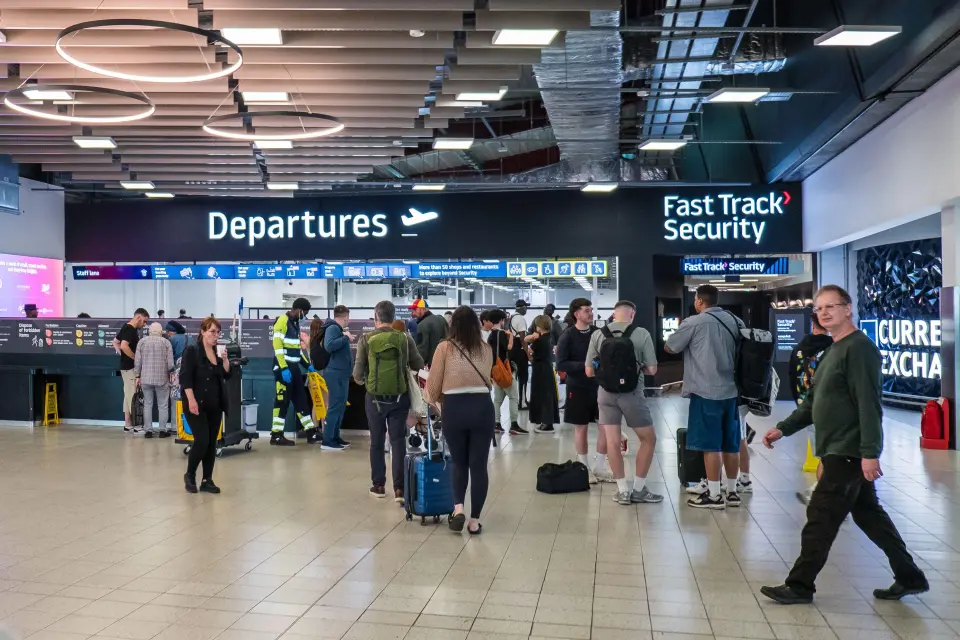

In [62]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions

1. Difference between an LLM and a multimodal model?
2. What additional information does the vision model receive?
3. Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

### Answers

1. A traditional LLM mainly processes text, while a multimodal model can process multiple types of input, such as text and images.
2. Besides the text prompt, the model receives the image encoded in Base64, allowing it to identify objects, describe the environment, and read visible text.
3. Local vision AI can be used for document analysis and OCR, industrial quality inspection, educational tools, medical-image preprocessing, and surveillance analysis. Running it locally can also help protect data privacy.

# Part 15 — Build a Local AI Web Application

**Structure:**
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [63]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\asus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [64]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [65]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


# Part 16 — Performance Benchmark

We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [66]:
!pip install -q psutil


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\asus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [67]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [68]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5,6.55,6.19,0.0,337.19,618.70,694,3.47,94.0,None
1,gemma3,3.35,2.89,0.0,167.74,319.55,818,6.84,73.1,None


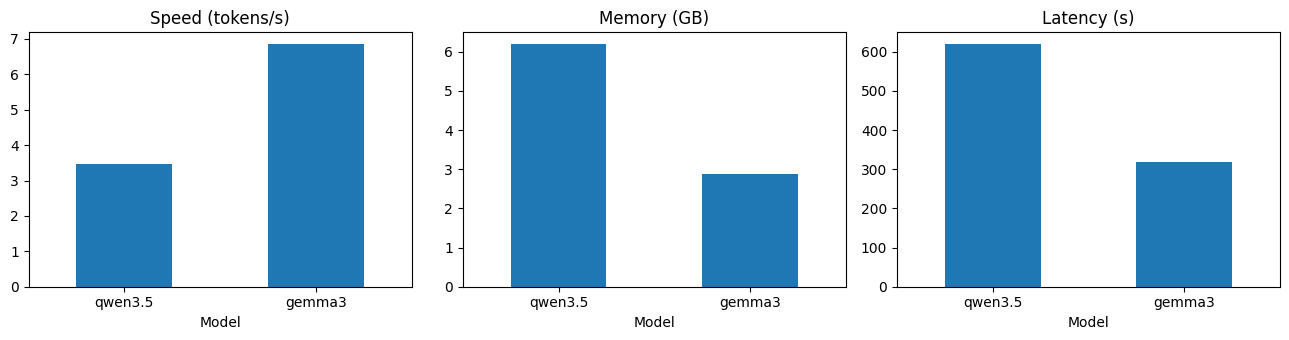

In [69]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```

The results show that model size affects speed and resource usage on my computer. Qwen 3.5 occupies 6.55 GB on disk and takes 337.19 seconds to respond, while Gemma 3 occupies 3.35 GB and takes 167.74 seconds. Gemma 3 also has a higher generation speed (6.84 tokens/s compared with 3.47 tokens/s) and lower system RAM usage (73.1% compared with 94%). Therefore, Gemma 3 is more suitable for my computer when speed and memory efficiency are priorities. However, the best model should also be evaluated based on the accuracy and quality of its responses, since a smaller model is not necessarily better for every task.

# Part 17 — Final Mini Project: FSTT Local AI Assistant

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [70]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [71]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [72]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [73]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [74]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [76]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "-u", "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

if server.poll() is not None:
    print("Server failed to start:")
    print(server.stdout.read())
else:
    try:
        r = requests.get("http://127.0.0.1:5001/", timeout=5)
        print("Server is running:", r.status_code)
    except requests.RequestException as e:
        print("Server started but is not responding:", e)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so we can open http://127.0.0.1:5001 — stop in the next cell

Server is running: 200
Q: What is reinforcement learning?
A: Reinforcement learning is a method where an agent learns through interaction with an environment using rewards and penalties. The agent observes a state, chooses an action, and receives a reward, with the goal of learning a policy that maximises cumulative reward. Common algorithms include Q-learning and policy gradients.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 422.75s · 1.7 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn a mapping from inputs to outputs.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 77.41s · 1.4 tok/s

Q: Summarize deep learning
A: {'difficulty': 'easy', 'key_points': ['Uses artificial neural networks with many layers.', 'L

In [77]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


# Part 18 — Questions for the Report

> LocalAI_Lab/ report.pdf

# Part 19 — Deliverables

Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [78]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
